# Evaluación 3 — Modelado predictivo de riesgo crediticio

**Asignatura:** Inteligencia Artificial  
**Integrantes:** *[Constanza Tapia, Maura Gonzalez, Samuel Loyola, Felipe Riquelme]*

## Contexto y objetivo

Una institución financiera necesita analizar solicitudes de créditos hipotecarios para estimar si un cliente podría incumplir el pago. Se trata de un problema de **clasificación supervisada**: conocemos ejemplos anteriores y entrenaremos un modelo para predecir nuevos casos.

La variable que debemos predecir es **`Riesgo_Impago`**:

- **0:** cliente que cumple sus pagos.
- **1:** cliente que incurre en impago.

Los errores tienen costos diferentes para el banco:

| Error | ¿Qué significa? | Costo de referencia |
|---|---|---:|
| Falso negativo (FN) | Predecir 0, pero el cliente realmente incumple (1). | \$1.500.000 |
| Falso positivo (FP) | Predecir 1, pero el cliente realmente cumple (0). | \$200.000 |

> **Importante:** el enunciado expresa los costos con `$` pero no especifica su moneda. Se respetará esa unidad sin asumir que sean dólares. Los ingresos y préstamos sí se describen en dólares en el diccionario de datos.

**Objetivo técnico:** comparar un árbol de decisión básico con uno ajustado mediante validación cruzada, evitando usar los datos de prueba durante el entrenamiento.  
**Objetivo de negocio:** detectar más impagos y analizar si la mejora justifica el posible aumento de rechazos erróneos.

El trabajo sigue las **cuatro fases de la evaluación** y utiliza `random_state=29`.

## Fase 1 — Diagnóstico y calidad de datos (EDA)

Antes de entrenar, debemos entender los datos. Revisaremos:

1. Cantidad de registros, columnas, tipos de datos y valores faltantes.
2. Registros duplicados e inconsistencias lógicas.
3. Valores extremos (*outliers*) mediante la regla del rango intercuartílico (IQR).
4. Distribución de `Riesgo_Impago` para identificar desbalance entre las clases.

Las cuatro variables predictoras son `Ingreso_Anual`, `Monto_Prestamo`, `Puntaje_Credito` y `Relacion_Deuda_Ingreso`.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 29
PREDICTORAS = [
    "Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito",
    "Relacion_Deuda_Ingreso"
]
OBJETIVO = "Riesgo_Impago"

url = "https://raw.githubusercontent.com/Faxsito/Datasets-Notebooks-IA/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv"

df_original = pd.read_csv(url)
print("Columnas originales:", df_original.columns.tolist())

df = df_original.drop(columns=["Unnamed: 0"], errors="ignore").copy()
columnas_esperadas = PREDICTORAS + [OBJETIVO]
if not set(columnas_esperadas).issubset(df.columns):
    raise ValueError("Faltan columnas requeridas para el modelo.")
if set(df.columns) != set(columnas_esperadas):
    print("Aviso: existen columnas adicionales; se utilizarán solo las definidas en el enunciado.")
df = df[columnas_esperadas]

print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
display(df.head())


Columnas originales: ['Unnamed: 0', 'Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso', 'Riesgo_Impago']
Dimensiones: 25,000 filas y 5 columnas


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,39785.55,85246.38,694.0,70.00,0
1,69773.95,244260.00,622.0,10.65,0
2,127770.68,209310.35,780.0,42.70,0
3,16799.80,213059.98,741.0,48.04,0
4,70229.83,219523.13,714.0,25.58,0


### 1.1 Estructura, estadísticos y faltantes

`info()` muestra los tipos de datos y `describe()` resume los valores numéricos. Revisamos faltantes por columna y duplicados **después de eliminar el índice exportado**, para que ese identificador no oculte registros repetidos.

In [22]:
print("=== INFORMACIÓN GENERAL ===")
df.info()

print("\n=== RESUMEN ESTADÍSTICO ===")
display(df.describe().T.round(2))

print("\n=== NULOS POR VARIABLE ===")
calidad = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% nulos": (100 * df.isna().mean()).round(2),
    "Tipo": df.dtypes.astype(str)
})
display(calidad)

print(f"Registros duplicados: {df.duplicated().sum()}")

=== INFORMACIÓN GENERAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 976.7 KB

=== RESUMEN ESTADÍSTICO ===


,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.44,29804.90,7832.12,35051.32,49234.68,68923.52,348135.55
Monto_Prestamo,25000.0,220162.89,60059.30,50000.00,179438.08,220241.47,261003.36,451784.21
Puntaje_Credito,25000.0,680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,25000.0,24.03,13.62,5.00,13.79,21.45,31.38,70.00
Riesgo_Impago,25000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00



=== NULOS POR VARIABLE ===


,Nulos,% nulos,Tipo
Ingreso_Anual,0,0.0,float64
Monto_Prestamo,0,0.0,float64
Puntaje_Credito,0,0.0,float64
Relacion_Deuda_Ingreso,0,0.0,float64
Riesgo_Impago,0,0.0,int64


Registros duplicados: 0


### 1.2 Inconsistencias lógicas

Según el enunciado, los ingresos y los montos deben ser positivos, el puntaje crediticio debe estar entre 300 y 850 y el objetivo debe contener únicamente 0 o 1. La relación deuda/ingreso (DTI) es un porcentaje: revisamos los valores negativos y los superiores a 100 %, aunque **superar 100 % no es automáticamente un error**, porque podría reflejar deudas mayores que los ingresos.

In [23]:
verificaciones = {
    "Ingreso anual <= 0": int((df["Ingreso_Anual"] <= 0).sum()),
    "Monto del préstamo <= 0": int((df["Monto_Prestamo"] <= 0).sum()),
    "Puntaje fuera de 300-850": int((~df["Puntaje_Credito"].between(300, 850)).sum()),
    "DTI < 0": int((df["Relacion_Deuda_Ingreso"] < 0).sum()),
    "DTI > 100 (revisar, no necesariamente error)": int((df["Relacion_Deuda_Ingreso"] > 100).sum()),
    "Target distinto de 0 o 1": int((~df[OBJETIVO].isin([0, 1])).sum()),
}
display(pd.DataFrame.from_dict(verificaciones, orient="index", columns=["Registros"]))

if verificaciones["Target distinto de 0 o 1"] > 0 or df[OBJETIVO].isna().any():
    raise ValueError("La variable objetivo contiene valores faltantes o distintos de 0/1.")

,Registros
Ingreso anual <= 0,0
Monto del préstamo <= 0,0
Puntaje fuera de 300-850,0
DTI < 0,0
"DTI > 100 (revisar, no necesariamente error)",0
Target distinto de 0 o 1,0


### 1.3 Valores extremos (*outliers*)

La regla **IQR** marca como extremos los valores menores a `Q1 - 1,5 × IQR` o mayores a `Q3 + 1,5 × IQR`, donde `IQR = Q3 - Q1`.

Un valor extremo **no es necesariamente un error**. Por ejemplo, un ingreso alto puede ser real. Por eso calcularemos cuántos hay en cada columna, pero no los eliminaremos sin evidencia de que sean inválidos.

,Límite inferior,Límite superior,Outliers (IQR),% sobre el total
Variable,,,,
Ingreso_Anual,-15756.99,119731.82,976,3.90
Monto_Prestamo,57090.15,383351.29,157,0.63
Puntaje_Credito,518.50,842.50,167,0.67
Relacion_Deuda_Ingreso,-12.60,57.78,663,2.65


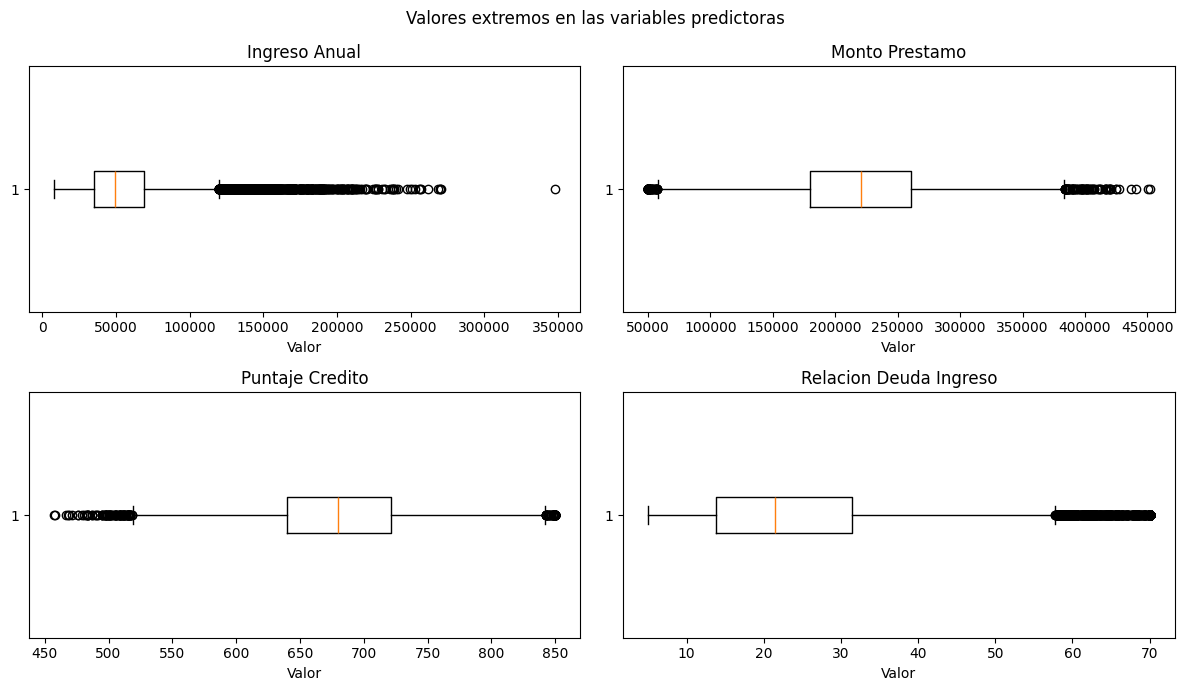

In [24]:
resultados_iqr = []
for columna in PREDICTORAS:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    extremos = (~df[columna].between(limite_inferior, limite_superior)).sum()
    resultados_iqr.append({
        "Variable": columna,
        "Límite inferior": round(limite_inferior, 2),
        "Límite superior": round(limite_superior, 2),
        "Outliers (IQR)": int(extremos),
        "% sobre el total": round(extremos / len(df) * 100, 2),
    })

resumen_outliers = pd.DataFrame(resultados_iqr).set_index("Variable")
display(resumen_outliers)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, columna in zip(axes.flat, PREDICTORAS):
    ax.boxplot(df[columna].dropna(), vert=False)
    ax.set_title(columna.replace("_", " "))
    ax.set_xlabel("Valor")
plt.suptitle("Valores extremos en las variables predictoras")
plt.tight_layout()
plt.show()

### 1.4 Desbalance de la variable objetivo

Si la mayoría de los clientes cumple, el modelo podría acertar mucho prediciendo siempre 0. Por eso necesitamos conocer el porcentaje real de cada clase antes de elegir las métricas.

,Cantidad,Porcentaje (%)
Riesgo_Impago,,
0,23211,92.84
1,1789,7.16


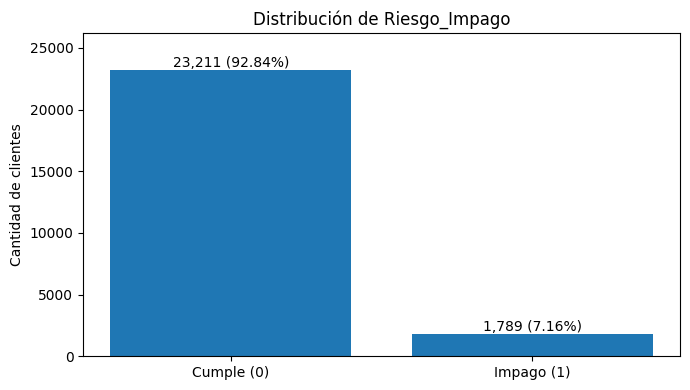

Exactitud de predecir siempre 0: 92.84%


In [25]:
conteos = df[OBJETIVO].value_counts().reindex([0, 1], fill_value=0)
porcentajes = 100 * conteos / conteos.sum()
display(pd.DataFrame({"Cantidad": conteos, "Porcentaje (%)": porcentajes.round(2)}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(["Cumple (0)", "Impago (1)"], conteos.values)
for barra, cantidad, porcentaje in zip(barras, conteos.values, porcentajes.values):
    ax.text(barra.get_x() + barra.get_width()/2, barra.get_height(),
            f"{cantidad:,} ({porcentaje:.2f}%)", ha="center", va="bottom")
ax.set_title("Distribución de Riesgo_Impago")
ax.set_ylabel("Cantidad de clientes")
ax.set_ylim(0, conteos.max() * 1.13)
plt.tight_layout()
plt.show()

print(f"Exactitud de predecir siempre 0: {porcentajes.loc[0]:.2f}%")

### Conclusión del EDA

En este archivo se observan **25.000 registros**, sin valores faltantes ni duplicados. Las comprobaciones de rangos y valores positivos no detectan inconsistencias. La regla IQR identifica valores extremos —entre ellos **976 ingresos anuales (3,90 %)**—, pero no tenemos evidencia suficiente para tratarlos como errores.

El hallazgo principal es el **desbalance**: aproximadamente **92,84 %** de los registros pertenece a la clase 0 y **7,16 %** a la clase 1. Por eso una exactitud (*accuracy*) alta puede ser engañosa: debemos observar específicamente la capacidad para detectar impagos.

## Fase 2 — Limpieza y tratamiento con un Pipeline

Usaremos un `ColumnTransformer` dentro de `Pipeline` para evitar **fuga de datos** (*data leakage*): el preprocesamiento se aprende solo con los datos de entrenamiento y luego se aplica a los de prueba.

1. `SimpleImputer(strategy="median")`: reemplaza eventuales valores numéricos faltantes por la mediana aprendida en entrenamiento. **En este CSV no hay nulos**, pero dejamos esta etapa por reutilización.
2. `StandardScaler()`: centra las variables y las escala según su desviación estándar. **No es escalado robusto**; además, un árbol de decisión no necesita escalado para decidir cortes, pero se mantiene como parte de un pipeline explícito y reproducible.

No es necesario codificar variables categóricas: las cuatro predictoras son numéricas. Tampoco eliminaremos outliers automáticamente.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = df[PREDICTORAS].copy()
y = df[OBJETIVO].copy()

pipeline_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
])

preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, PREDICTORAS)
])

print("Predictoras:", X.columns.tolist())
print("Variable objetivo:", y.name)
print("Preprocesamiento definido; todavía no se ha ajustado con datos.")

Predictoras: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']
Variable objetivo: Riesgo_Impago
Preprocesamiento definido; todavía no se ha ajustado con datos.


## Fase 3 — Construcción de modelos

Usaremos una división **80 % entrenamiento / 20 % prueba**, `random_state=29` y `stratify=y` para conservar aproximadamente la proporción de cumplidores e impagos en ambos conjuntos.

- **Línea base:** `DecisionTreeClassifier(random_state=29)` con parámetros del árbol por defecto.
- **Optimizado:** el mismo tipo de árbol, pero con `GridSearchCV` y validación cruzada de 5 particiones sobre los **datos de entrenamiento**. Se probarán cinco hiperparámetros: profundidad máxima, tamaño mínimo para dividir, mínimo de registros en hojas, criterio de impureza y ponderación de clases.

El criterio de selección durante la búsqueda será **F1 de la clase 1**. Más adelante evaluaremos por separado el costo financiero; por ello, *optimizado* aquí significa **optimizado según F1 en validación cruzada**, no necesariamente el mínimo costo posible.

In [27]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Entrenamiento: {len(X_train):,} registros ({len(X_train)/len(X):.0%})")
print(f"Prueba: {len(X_test):,} registros ({len(X_test)/len(X):.0%})")
print("\nDistribución de clases:")
display(pd.DataFrame({
    "Train (%)": (100 * y_train.value_counts(normalize=True).reindex([0,1])).round(2),
    "Test (%)": (100 * y_test.value_counts(normalize=True).reindex([0,1])).round(2),
}))

Entrenamiento: 20,000 registros (80%)
Prueba: 5,000 registros (20%)

Distribución de clases:


,Train (%),Test (%)
Riesgo_Impago,,
0,92.84,92.84
1,7.16,7.16


In [28]:
# Modelo inicial: no ajustamos todavía ningún hiperparámetro del árbol.
modelo_base = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("arbol", DecisionTreeClassifier(random_state=RANDOM_STATE))
])
modelo_base.fit(X_train, y_train)
print("Árbol de decisión de línea base entrenado.")

Árbol de decisión de línea base entrenado.


In [ ]:
# Cinco hiperparámetros: 5 x 4 x 4 x 2 x 2 = 320 combinaciones.
param_grid = {
    "arbol__max_depth": [3, 5, 8, 12, None],
    "arbol__min_samples_split": [2, 5, 10, 20],
    "arbol__min_samples_leaf": [1, 2, 5, 10],
    "arbol__criterion": ["gini", "entropy"],
    "arbol__class_weight": [None, "balanced"],
}

modelo_a_optimizar = Pipeline(steps=[
    ("preprocesamiento", preprocesamiento),
    ("arbol", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

busqueda = GridSearchCV(
    estimator=modelo_a_optimizar,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=1,
    refit=True,
    verbose=0
)
busqueda.fit(X_train, y_train)
modelo_optimizado = busqueda.best_estimator_

print("Combinaciones evaluadas:", len(busqueda.cv_results_["params"]))
print(f"Mejor F1 medio en validación cruzada: {busqueda.best_score_:.4f}")
print("Mejores hiperparámetros:")
for parametro, valor in busqueda.best_params_.items():
    print(f"  {parametro}: {valor}")

## Fase 4 — Evaluación, matrices de confusión e impacto financiero

Evaluaremos los dos modelos **solo sobre el conjunto de prueba**, que no fue utilizado para entrenarlos ni para elegir los hiperparámetros.

### Las dos métricas seleccionadas

1. **Recall de la clase 1 (impago):** de todos los clientes que realmente incumplen, qué proporción identificamos. Es relevante porque cada impago no detectado (FN) representa la pérdida más alta del enunciado.
2. **F1-Score de la clase 1:** media armónica de precisión y recall. Permite observar el equilibrio entre detectar impagos y no generar demasiadas alertas incorrectas; resulta más informativa que accuracy en este conjunto desbalanceado.

El **costo financiero** se calculará adicionalmente como una interpretación de negocio basada en la matriz de confusión; **no es una tercera métrica de clasificación seleccionada**.

In [ ]:
from sklearn.metrics import recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

pred_base = modelo_base.predict(X_test)
pred_opt = modelo_optimizado.predict(X_test)

comparacion_metricas = pd.DataFrame({
    "Modelo": ["Línea base", "Optimizado"],
    "Recall (clase 1)": [
        recall_score(y_test, pred_base, pos_label=1),
        recall_score(y_test, pred_opt, pos_label=1),
    ],
    "F1-Score (clase 1)": [
        f1_score(y_test, pred_base, pos_label=1),
        f1_score(y_test, pred_opt, pos_label=1),
    ],
}).set_index("Modelo")

display(comparacion_metricas.round(4))

# Orden de etiquetas: filas = realidad (0, 1); columnas = predicción (0, 1).
matriz_base = confusion_matrix(y_test, pred_base, labels=[0, 1])
matriz_opt = confusion_matrix(y_test, pred_opt, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre, matriz in [
    (axes[0], "Línea base", matriz_base),
    (axes[1], "Optimizado", matriz_opt),
]:
    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz, display_labels=["Cumple (0)", "Impago (1)"]
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
plt.suptitle("Matrices de confusión en el conjunto de prueba")
plt.tight_layout()
plt.show()

### Interpretación de las cuatro casillas

Como la clase positiva es **1 = impago**, la matriz se interpreta así:

| | Predicho 0 (cumple) | Predicho 1 (impago) |
|---|---|---|
| **Real 0 (cumple)** | **VN:** cumplidor correctamente identificado; puede evaluarse como cliente de bajo riesgo. | **FP:** cumplidor marcado como riesgoso; se pierde la oportunidad de concederle un crédito viable. |
| **Real 1 (impago)** | **FN:** impago no detectado; el banco podría otorgar un crédito que terminaría sin pagarse. | **VP:** impago correctamente identificado; el banco puede evaluar medidas para reducir ese riesgo. |

Los **falsos negativos** son más costosos que los falsos positivos según el enunciado. Por eso no basta con mirar únicamente cuántas predicciones acierta cada árbol.

In [ ]:
COSTO_FN = 1_500_000
COSTO_FP = 200_000

def monto(numero):
    """Da formato a los montos sin asumir una moneda no especificada."""
    return "$" + format(int(numero), ",").replace(",", ".")

def analizar_matriz(nombre, matriz):
    vn, fp, fn, vp = matriz.ravel()
    costo_fn = fn * COSTO_FN
    costo_fp = fp * COSTO_FP
    return {
        "Modelo": nombre,
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn),
        "VP": int(vp),
        "Costo FP": int(costo_fp),
        "Costo FN": int(costo_fn),
        "Costo total": int(costo_fp + costo_fn),
    }

impacto = pd.DataFrame([
    analizar_matriz("Línea base", matriz_base),
    analizar_matriz("Optimizado", matriz_opt),
]).set_index("Modelo")

print("=== MATRICES TRADUCIDAS A NEGOCIO ===")
display(impacto[["VN", "FP", "FN", "VP"]])

print("=== COSTO ESTIMADO DE LOS ERRORES (CONJUNTO DE PRUEBA) ===")
display(impacto[["Costo FP", "Costo FN", "Costo total"]].map(monto))

diferencia = impacto.loc["Línea base", "Costo total"] - impacto.loc["Optimizado", "Costo total"]
print("Diferencia de costo (base - optimizado):", monto(diferencia))

for nombre in impacto.index:
    r = impacto.loc[nombre]
    print(f"\n{nombre}:")
    print(f"  VN = {r['VN']}: clientes cumplidores identificados correctamente.")
    print(f"  VP = {r['VP']}: impagos detectados correctamente.")
    print(f"  FP = {r['FP']}: clientes cumplidores marcados como impagos.")
    print(f"  FN = {r['FN']}: impagos que el modelo no detectó.")
    print(f"  Costo = {monto(r['Costo FN'])} por FN + {monto(r['Costo FP'])} por FP = {monto(r['Costo total'])}.")

### Conclusiones e interpretación para el banco

En el conjunto de prueba de **5.000 solicitudes**, comparamos los resultados:

| Resultado | Línea base | Modelo optimizado |
|---|---:|---:|
| Verdaderos negativos (VN) | 4.363 | 3.771 |
| Falsos positivos (FP) | 279 | 871 |
| Falsos negativos (FN) | 246 | 121 |
| Verdaderos positivos (VP) | 112 | 237 |
| Recall de impago | 31,28 % | 66,20 % |
| Costo estimado de errores | **\$424.800.000** | **\$355.700.000** |

**Interpretación:** el modelo optimizado identifica **125 impagos adicionales**, aunque produce **592 falsos positivos adicionales**. Aplicando los costos de la evaluación a estos 5.000 casos de prueba, el costo estimado es **\$69.100.000 menor** con el modelo optimizado.

**Decisión razonada:** en esta muestra, el árbol ajustado según F1 obtiene un mejor resultado financiero bajo los costos indicados. Esto **no garantiza** un ahorro futuro idéntico ni implica que los préstamos deban rechazarse automáticamente. Antes de utilizarlo en decisiones reales se requerirían validación adicional, reglas de negocio y supervisión humana.

**Limitación:** las variables del CSV describen solo una parte de la situación financiera de cada solicitante. El cálculo usa costos fijos por tipo de error, como plantea el ejercicio, y no calcula el costo individual real de cada préstamo.
